# Mass properties

`mass_properties` integrates a density over a body and reports its **mass**, **centre of mass**, **inertia tensor**, **principal moments and axes** and **radii of gyration** — for a volume mesh, for the body a closed surface encloses, or for a thin shell. [`compute_stats`](https://github.com/loumalouomega/meshioplusplus/blob/master/doc/stats.md) reports the mean of the points as its `centroid`; that is not the centre of mass of a body whose cells differ in size or density.

This notebook checks the operation against closed forms and draws the centre of mass and principal axes. The CLI form is `meshioplusplus mass part.stl --density 7850 --json`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp

try:  # PyVista off-screen rendering when a GL context exists
    import pyvista as pv
    pv.OFF_SCREEN = True
    pv.set_jupyter_backend('static')
except Exception:  # pragma: no cover - head-less fallback to matplotlib below
    pv = None


def draw(mesh, entry, title, scale=0.6):
    """Draw the skin of `mesh`, the centre of mass and the principal axes."""
    skin = mp.extract_surface(mesh) if any(b.type in ('hexahedron', 'tetra') for b in mesh.cells) else mesh
    pts = np.asarray(skin.points)
    fig = plt.figure(figsize=(7, 5.5))
    ax = fig.add_subplot(projection='3d')
    polys = []
    for block in skin.cells:
        if block.type in ('triangle', 'quad'):
            polys += [pts[np.asarray(c)] for c in block.data]
    ax.add_collection3d(Poly3DCollection(polys, facecolors='#2ec4b6', edgecolors='#1f4e79',
                                         linewidths=0.3, alpha=0.35))
    c = np.asarray(entry['centre'])
    axes = np.asarray(entry['principal_axes']).reshape(3, 3)
    extent = np.ptp(pts, axis=0).max()
    for k, colour in enumerate(('#d62828', '#2a9d8f', '#264653')):
        v = axes[:, k] * extent * scale / 2
        ax.plot(*zip(c - v, c + v), color=colour, linewidth=2.5)
    ax.scatter(*c, color='k', s=60, label='centre of mass')
    mean = pts.mean(axis=0)
    ax.scatter(*mean, color='orange', marker='x', s=70, label='mean of the points')
    lo, hi = pts.min(axis=0), pts.max(axis=0)
    mid, half = (lo + hi) / 2, (hi - lo).max() / 2
    ax.set_xlim(mid[0] - half, mid[0] + half)
    ax.set_ylim(mid[1] - half, mid[1] + half)
    ax.set_zlim(mid[2] - half, mid[2] + half)
    ax.set_title(title)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()

## A box against its closed form

A 2 × 3 × 4 box of density 2 has mass 48 and the inertia `m (b² + c²) / 12` about each axis.

kind     solid
mass     47.99999999999999 (expected 48)
centre   [1.0, 1.5, 2.0]
inertia  [100.  80.  52.] expected [99.99999999999999, 79.99999999999999, 51.99999999999999]
moments  [ 52.  80. 100.]


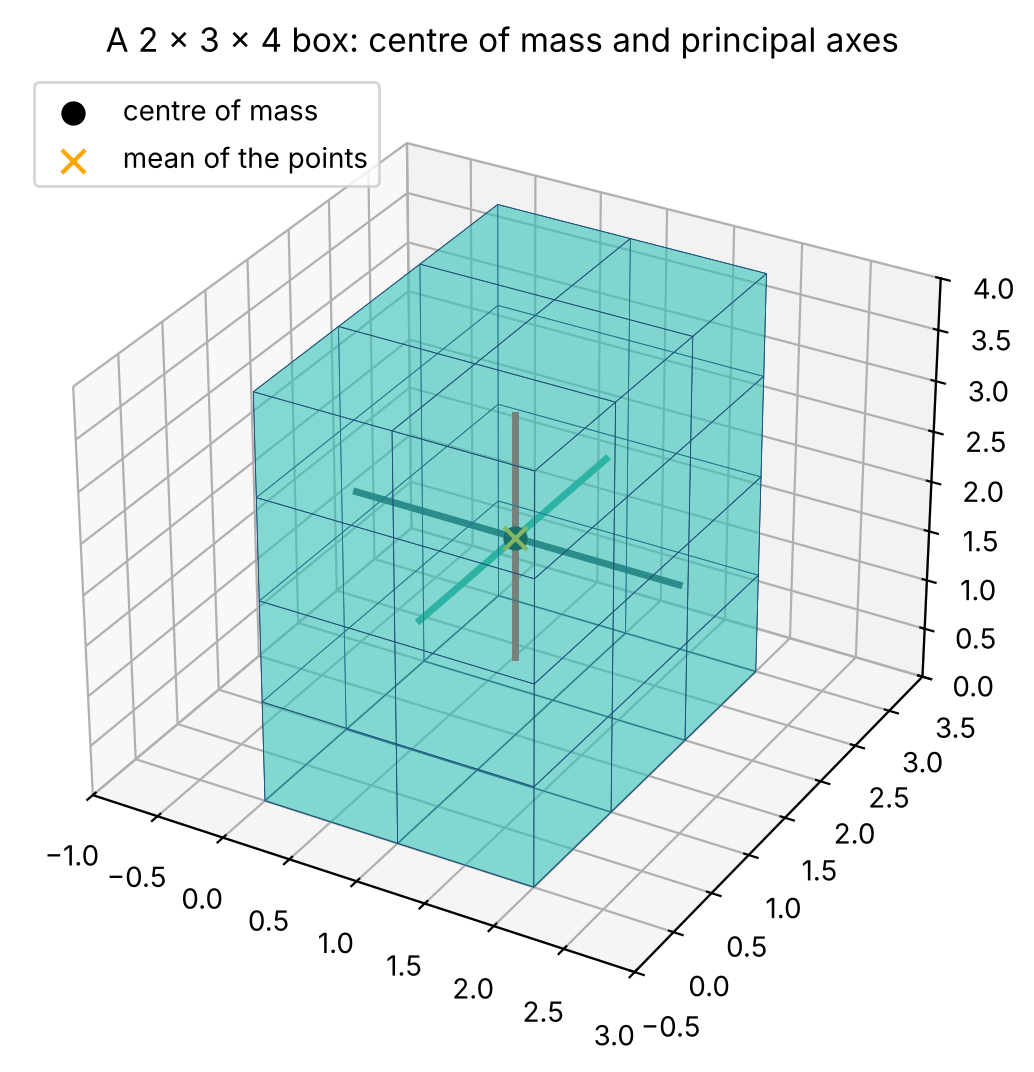

In [2]:
box = mp.box(dims=(2, 3, 4), size=(2.0, 3.0, 4.0))
r = mp.mass_properties(box, density=2.0)
t = r['total']
m = t['mass']
print('kind    ', r['kind'])
print('mass    ', t['mass'], '(expected 48)')
print('centre  ', t['centre'])
print('inertia ', np.round(t['inertia'][:3], 6), 'expected', [m * 25 / 12, m * 20 / 12, m * 13 / 12])
print('moments ', np.round(t['principal_moments'], 6))
draw(box, t, 'A 2 x 3 x 4 box: centre of mass and principal axes')

## Cells that differ in density

`density_array` names a scalar `cell_data` array. Here the right half of a bar is eight times denser, so the centre of mass moves away from the mean of the points, which is what `compute_stats` reports as its `centroid`.

mass               17.999999999999993 (expected 18.0 )
centre of mass x   2.777777777777778
mean of the points 2.0


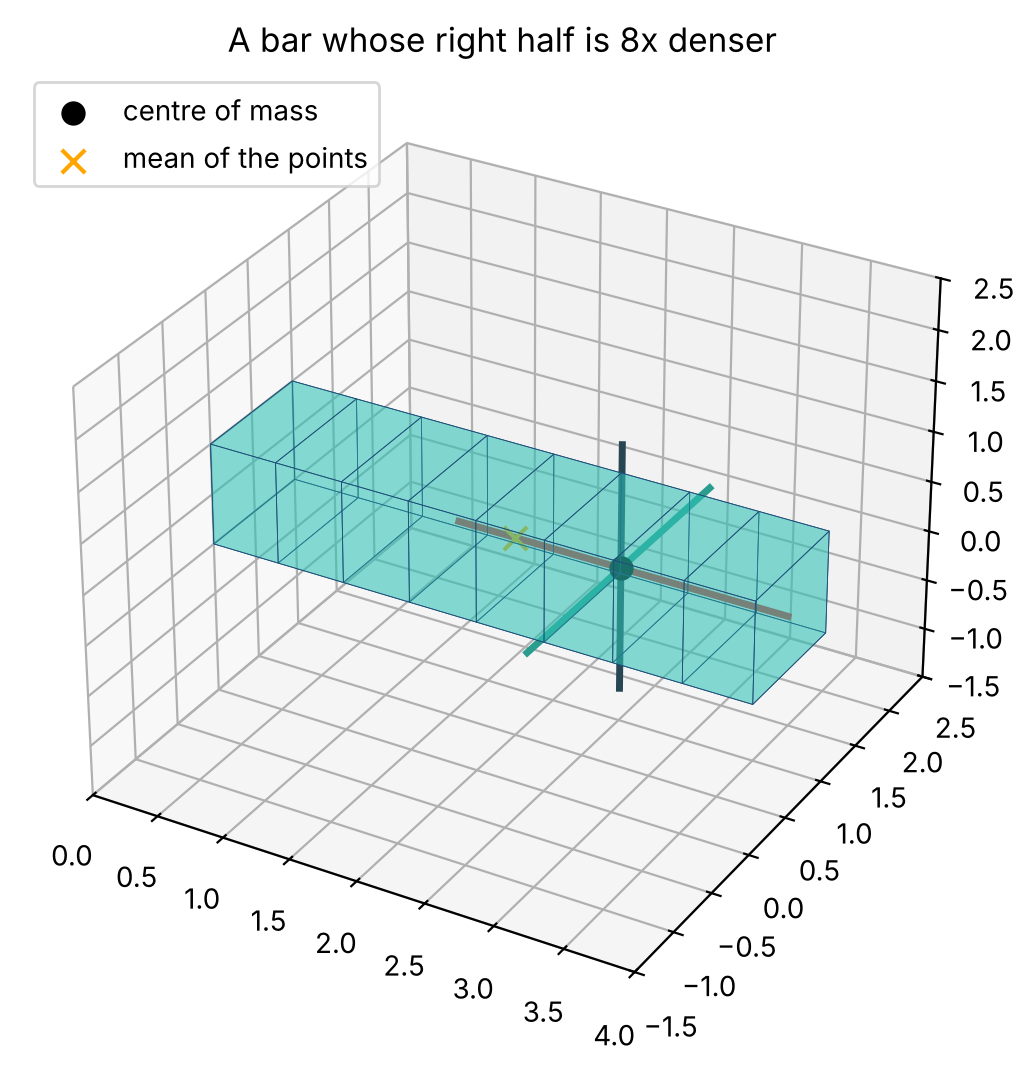

In [3]:
bar = mp.box(dims=(8, 1, 1), size=(4.0, 1.0, 1.0))
rho = np.where(np.arange(8) < 4, 1.0, 8.0)
bar.cell_data['rho'] = [rho]
r = mp.mass_properties(bar, density_array='rho')
t = r['total']
print('mass              ', t['mass'], '(expected', 2.0 * 1.0 + 2.0 * 8.0, ')')
print('centre of mass x  ', t['centre'][0])
print('mean of the points', mp.compute_stats(bar)['centroid'][0])
draw(bar, t, 'A bar whose right half is 8x denser')

## A closed surface and a shell

A closed, consistently wound triangle surface encloses a body, integrated by the divergence theorem (exact for a polyhedron). A UV sphere of radius 1 approaches the volume 4π/3 and the inertia `2/5 m r²` of a solid ball as it is refined. An open surface needs a `thickness`, which turns it into a shell.

nu= 16 nv=  8  volume 3.92660 (4pi/3 = 4.18879)  Ixx/(m r^2) 0.38487 (0.4)
nu= 32 nv= 16  volume 4.12194 (4pi/3 = 4.18879)  Ixx/(m r^2) 0.39616 (0.4)
nu= 64 nv= 32  volume 4.17200 (4pi/3 = 4.18879)  Ixx/(m r^2) 0.39904 (0.4)


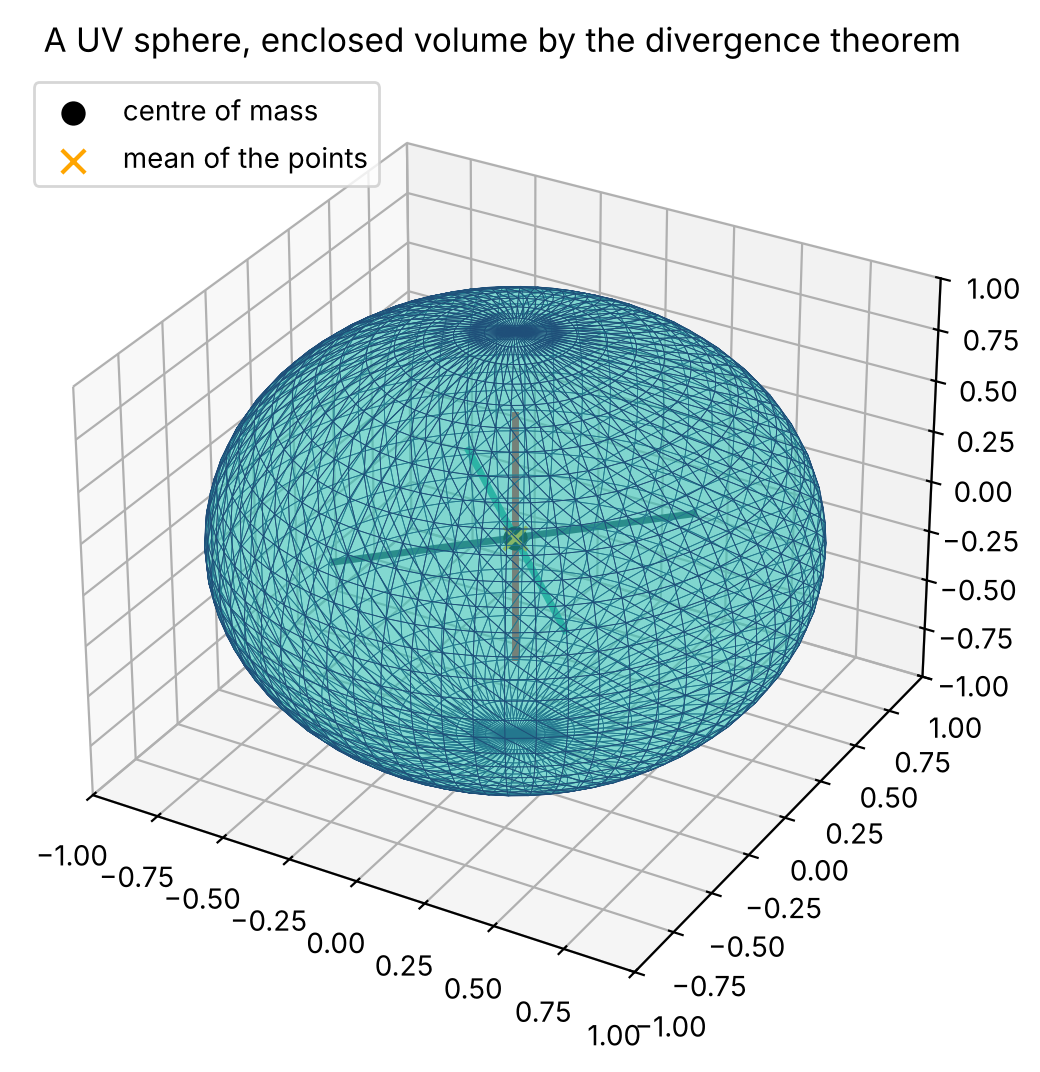

open surface refused: meshio++: mass_properties: the surface is not a closed, consistently wound surfa ...
shell mass 8.0 Izz 3.333333333333333 (m (a^2+b^2)/12 = 3.3333333333333335 )


In [4]:
for nu, nv in [(16, 8), (32, 16), (64, 32)]:
    ball = mp.uv_sphere(radius=1.0, nu=nu, nv=nv)
    t = mp.mass_properties(ball)['total']
    print(f'nu={nu:3d} nv={nv:3d}  volume {t["measure"]:.5f} (4pi/3 = {4*np.pi/3:.5f})  '
          f'Ixx/(m r^2) {t["inertia"][0]/t["mass"]:.5f} (0.4)')
draw(ball, t, 'A UV sphere, enclosed volume by the divergence theorem')

plate = mp.Mesh([[0, 0, 0], [2, 0, 0], [2, 1, 0], [0, 1, 0]], [('quad', [[0, 1, 2, 3]])])
try:
    mp.mass_properties(plate)
except ValueError as exc:
    print('open surface refused:', str(exc)[:80], '...')
s = mp.mass_properties(plate, density=8.0, thickness=0.5)
print(s['kind'], 'mass', s['total']['mass'], 'Izz', s['total']['inertia'][2], '(m (a^2+b^2)/12 =', 8.0*0.5*2*5/12, ')')